## ITNPA4-34 Project (Q3 & Q4)

### Question 3

In [20]:
import os
import warnings
import pandas as pd
import numpy as np
import re
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from collections import Counter
from sklearn.metrics.pairwise import cosine_similarity
import gensim
from gensim.corpora import Dictionary 
from gensim.models import LdaModel
import pyLDAvis

warnings.filterwarnings('ignore')


### 3.1.

In [21]:
# Read Corpus
corpus_dir = 'research_corpus'
num_docs = 5
research_corpus = []

for i in range(num_docs):
    file_path = os.path.join(corpus_dir, f'research_{i+1}.txt')
    
    with open(file_path, 'r', encoding='utf-8') as file:
        text = file.read()
        research_corpus.append(text)

df = pd.DataFrame(
    research_corpus,
    columns = ['articles'],
    index = [f"research_{i+1}" for i in range(num_docs)]
)

df

,articles
research_1,The purposes of this article are to position m...
research_2,"Now I see it, now I don’t:\nresearcher’s posit..."
research_3,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...
research_4,Abstract\nCronbach’s alpha is a statistic comm...
research_5,Denzin’s Paradigm Shift: Revisiting Triangulat...


### 3.2.

In [22]:
# Preprocess

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    
    # Lowercase
    text = text.lower()

    # Regex
    regex_pattern = r'[^A-Za-z\s]'
    whitespace = r'\s+'

    clean_text = re.sub(regex_pattern, ' ', text)
    clean_text = re.sub(whitespace, ' ', clean_text)

    # Tokenize
    tokens = word_tokenize(clean_text)

    # Remove stop words
    clean_tokens = [token for token in tokens if token not in stop_words and len(token) > 2]

    # Lemmatize
    lemmatized_tokens = [lemmatizer.lemmatize(token) for token in clean_tokens]
    
    # Append lists
    joined_tokens = " ".join(lemmatized_tokens)

    return joined_tokens

df['clean_articles'] = df['articles'].apply(preprocess)
df.head()

,articles,clean_articles
research_1,The purposes of this article are to position m...,purpose article position mixed method research...
research_2,"Now I see it, now I don’t:\nresearcher’s posit...",see researcher position reflexivity qualitativ...
research_3,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...,developmental research study instructional des...
research_4,Abstract\nCronbach’s alpha is a statistic comm...,abstract cronbach alpha statistic commonly quo...
research_5,Denzin’s Paradigm Shift: Revisiting Triangulat...,denzin paradigm shift revisiting triangulation...


### 3.3.

In [24]:
# Term Frequency Summarisation

# Aggregate Remaining Articles and Tokenise Sentences
raw_text = df['articles'].iloc[0]
sentences = sent_tokenize(raw_text)

def content_words(sentence): 
    words = re.findall(r'[a-z]+', sentence.lower()) 
    return [w for w in words if w not in stop_words and len(w) > 2]

# Keep only sentences with meaningful semantic content
valid_sentences = [s for s in sentences if len(content_words(s)) > 2] 
all_content_words = [w for s in valid_sentences for w in content_words(s)] 
global_word_freq = Counter(all_content_words)

# Score each sentence
scores = [] 
for s in valid_sentences: 
    words = content_words(s) 
    sentence_score = sum(global_word_freq[w] for w in words) / len(words) 
    scores.append(sentence_score) 
    
scores = np.array(scores) 

# Top 3 sentence summary 
top_n = 3 
top_indices = sorted(np.argsort(scores)[-top_n:]) 
tf_summary = ' '.join([valid_sentences[i] for i in top_indices]) 
 
print('=' * 70) 
print('Term Frequency Summary of Research Article 1') 
print('=' * 70) 
print(tf_summary)

Term Frequency Summary of Research Article 1
Mixed methods research as the third research
paradigm can also help bridge the schism between quantitative
and qualitative research (Onwuegbuzie & Leech, 2004a). Our purpose in writing this article is to present mixed methods research as the third research paradigm in educational research.5 We hope the field will move beyond quantitative versus
qualitative research arguments because, as recognized by mixed
methods research, both quantitative and qualitative research are
important and useful. Mixed methods research as the third research
paradigm can also help bridge the schism between quantitative
and qualitative research (Onwuegbuzie & Leech, 2004a).


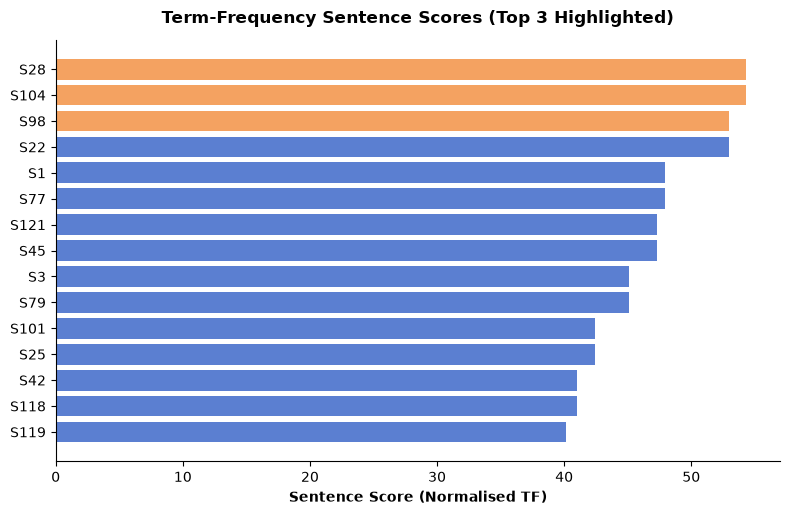

In [25]:
# Visualisation
def show_scores(sents, scores, title, top_k=15): 

    num_sents = len(sents)
    display_indices = np.argsort(scores)[-top_k:] 

    labels = [f'S{i+1}' for i in display_indices] 
    subset_scores = scores[display_indices] 
    
    top_3_set = set(np.argsort(scores)[-3:]) 
    colors = [ 
        '#F4A261' if i in top_3_set else '#5B7FD1' for i in display_indices 
    ] 
    
    fig, ax = plt.subplots(figsize=(8, max(4, len(display_indices) * 0.35))) 
    ax.barh(labels, subset_scores, color=colors) 
    ax.set_xlabel('Sentence Score (Normalised TF)', fontweight='bold') 
    ax.set_title( f'{title} (Top 3 Highlighted)', fontsize=12, fontweight='bold', pad=12 ) 
    
    ax.spines['top'].set_visible(False) 
    ax.spines['right'].set_visible(False) 
    plt.tight_layout() 
    plt.show() 
    
show_scores(valid_sentences, scores, 'Term-Frequency Sentence Scores', top_k=15 )    

### 3.4.

In [26]:
# Graph-Based TextRank Summarisation

remaining_df = df.iloc[1:].copy() 
raw_text = " ".join(remaining_df['articles'].dropna().tolist())
sentences = sent_tokenize(raw_text)

# Build TF-IDF sentence matrix and cosine similarity graph
vectorizer = TfidfVectorizer(stop_words = 'english')
X_sents = vectorizer.fit_transform(sentences)
sim_matrix = cosine_similarity(X_sents)
np.fill_diagonal(sim_matrix, 0)

# Run PageRank on the similarity graph
graph = nx.from_numpy_array(sim_matrix)
scores = nx.pagerank(graph)

# Select top n sentences and preserve original text order
top_n = 3
top_indices = sorted(sorted(scores, key=scores.get, reverse=True)[:top_n])
textrank_summary = " ".join([sentences[i] for i in top_indices])

print("=" * 60)
print(f"TextRank Graph-Based Summary of Remaining {len(remaining_df)} Research Articles")
print("=" * 60)
print(textrank_summary)

TextRank Graph-Based Summary of Remaining 4 Research Articles
In its simplest form,
developmental research can be either
 the study of the process and impact of specific instructional
design and development efforts; or
 a situation in which someone is performing instructional design, development, or evaluation activities and studying the
process at the same time; or
 the study of the instructional design, development, and evaluation process as a whole or of particular process components. Keywords: triangulation, Denzin, validity, reliability, confirmability, transferability, qualitative
research, multiple data source, multiple data collection methods, mitigating bias, data saturation,
social change
Introduction
Researchers often use a qualitative methodology to address social change despite the fact that most
research does not study social change, per se. Qualitative Research and Triangulation
The application of triangulation (multiple sources of data) can enhance the reliability of

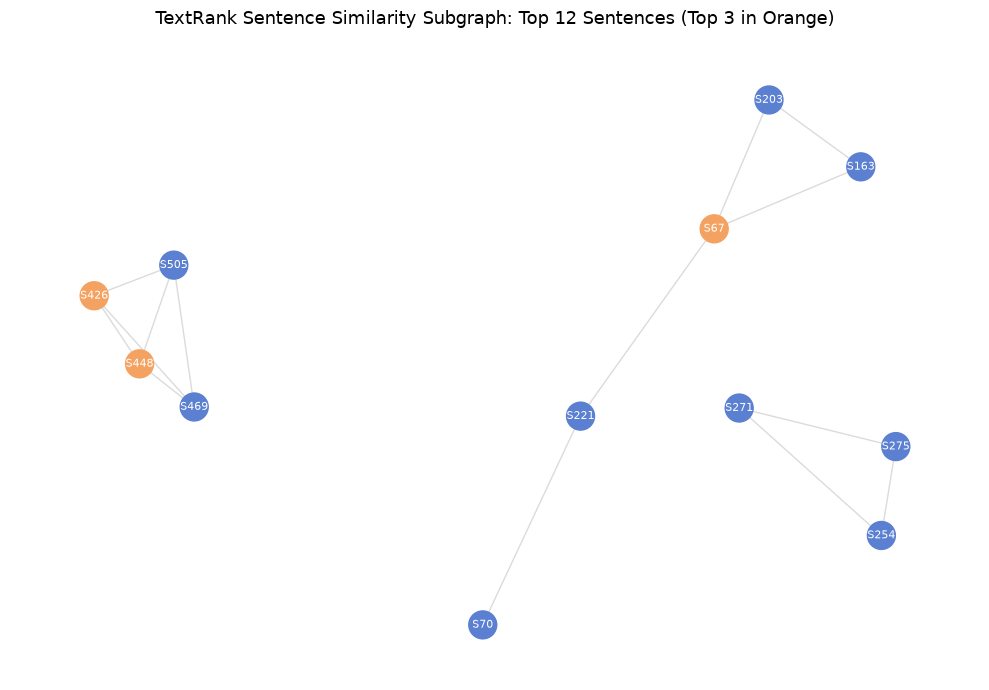

In [27]:
# Visualise only top 12 highest-scoring sentences for readability
top_k = 12
top_sentence_indices = sorted(scores, key=scores.get, reverse=True)[:top_k]

# Induce a subgraph containing only these key nodes
subgraph = graph.subgraph(top_sentence_indices).copy()

# Filter out weak edges (thresholding)
edge_threshold = 0.15
edges_to_remove = [
    (u, v)
    for u, v, d in subgraph.edges(data=True)
    if d.get("weight", 0) < edge_threshold
]

subgraph.remove_edges_from(edges_to_remove)

# Position layout with extra spacing
pos = nx.spring_layout(subgraph, k=0.5, seed=42)

# Set node sizes proportional to PageRank score
node_sizes = [scores[i] * 1200 + 400 for i in subgraph.nodes()]

# Highlight the top 3 summary sentences in orange, the rest in blue
top_n = set(top_indices)
node_colors = [ "#F4A261" if i in top_n else "#5B7FD1" for i in subgraph.nodes() ]

plt.figure(figsize=(10, 7))

nx.draw_networkx_nodes(
    subgraph, 
    pos, 
    node_size=node_sizes,
    node_color=node_colors, 
    alpha=1
)

nx.draw_networkx_edges(
    subgraph, 
    pos, 
    alpha=0.3, 
    edge_color="#888888")


labels = {i: f"S{i+1}" for i in subgraph.nodes()} 
nx.draw_networkx_labels( 
    subgraph, 
    pos, 
    labels=labels, 
    font_size=8, 
    font_color="white" 
) 

plt.title( f"TextRank Sentence Similarity Subgraph: Top {top_k} Sentences (Top 3 in Orange)", fontsize=13, pad=15, ) 
plt.axis("off") 
plt.tight_layout() 
plt.show()

### Question 4

### 4.1.

In [28]:
# Prepare Tokens and Gensim BoW Corpus

tokenized_docs = [doc.split() for doc in df['clean_articles']] 

dictionary = Dictionary(tokenized_docs) 

dictionary.filter_extremes(no_below=2, no_above=0.5) 
bow_corpus = [dictionary.doc2bow(doc) for doc in tokenized_docs] 

print(f"Total documents: {len(bow_corpus)}") 
print(f"Vocabulary size: {len(dictionary)}")

Total documents: 5
Vocabulary size: 463


In [29]:
# Train LDA Model
num_topics = 3 

ldamodel = LdaModel( 
    corpus=bow_corpus, 
    num_topics=num_topics, 
    id2word=dictionary, 
    passes=20, 
    alpha='auto', 
    eta='auto', 
    random_state=42, 
)

print("\n" + "=" * 70) 
print(f"LATENT DIRICHLET ALLOCATION (LDA): TOP {num_topics} TOPICS") 
print("=" * 70) 

topics = ldamodel.show_topics( 
    num_topics=num_topics, 
    num_words=10, 
    formatted=False 
) 

for topic_id, word_weights in topics: 
    top_words = [word for word, _ in word_weights] 
    dist_str = " + ".join([f"{weight:.3f}*{word}" for word, weight in word_weights[:6]]) 
    print(f"\nTopic {topic_id + 1}:") 
    print(f" Key Words: {', '.join(top_words)}") 
    print(f" Distribution: {dist_str} ...")


LATENT DIRICHLET ALLOCATION (LDA): TOP 3 TOPICS

Topic 1:
 Key Words: alpha, cronbach, reliability, item, education, test, paper, consistency, measure, high
 Distribution: 0.110*alpha + 0.061*cronbach + 0.048*reliability + 0.039*item + 0.031*education + 0.026*test ...

Topic 2:
 Key Words: mixed, epistemological, philosophical, called, strong, observation, test, written, versus, epistemology
 Distribution: 0.080*mixed + 0.014*epistemological + 0.014*philosophical + 0.014*called + 0.014*strong + 0.011*observation ...

Topic 3:
 Key Words: participant, product, mixed, personal, interview, system, production, situation, technology, program
 Distribution: 0.017*participant + 0.017*product + 0.017*mixed + 0.016*personal + 0.012*interview + 0.011*system ...


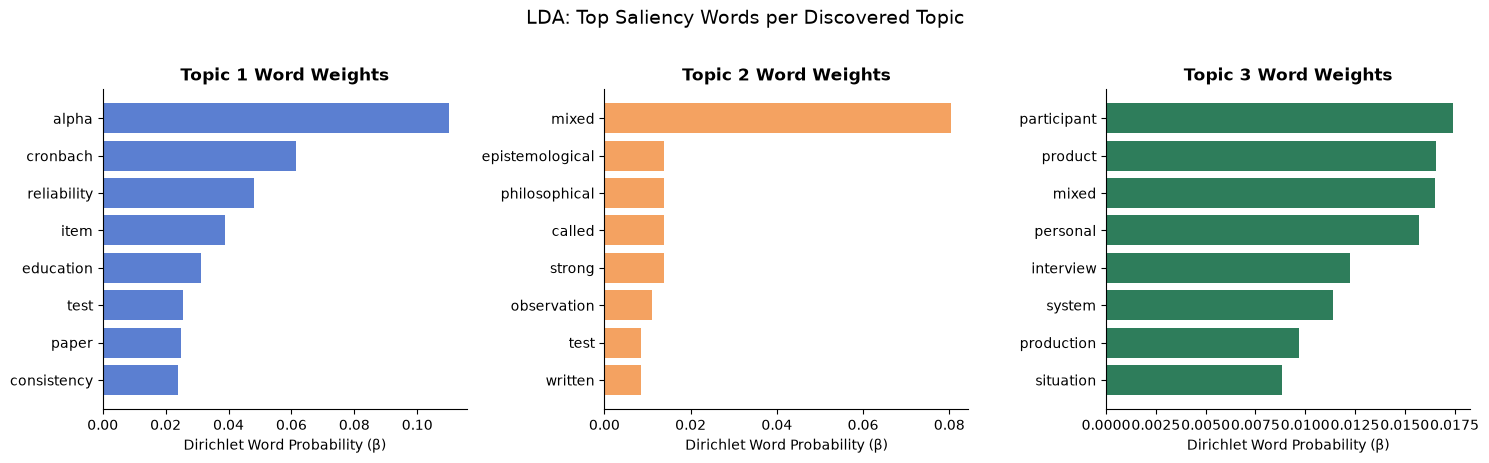

In [30]:
# Visualisation 1: Top Word Weights Per Topic 
fig, axes = plt.subplots(1, num_topics, figsize=(5 * num_topics, 4.5), sharey=False) 
if num_topics == 1: 
    axes = [axes] 
    
colors = ["#5B7FD1", "#F4A261", "#2E7D5B", "#9B59B6"] 

for topic_id, word_weights in topics: 
    ax = axes[topic_id] 
    words = [w for w, _ in word_weights[:8]][::-1] 
    weights = [wt for _, wt in word_weights[:8]][::-1] 
    
    ax.barh(words, weights, color=colors[topic_id % len(colors)]) 
    ax.set_title(f"Topic {topic_id + 1} Word Weights", fontweight="bold") 
    ax.set_xlabel("Dirichlet Word Probability (β)") 
    ax.spines["top"].set_visible(False) 
    ax.spines["right"].set_visible(False) 
    
plt.suptitle("LDA: Top Saliency Words per Discovered Topic", fontsize=14, y=1.02) 
plt.tight_layout() 
plt.show()

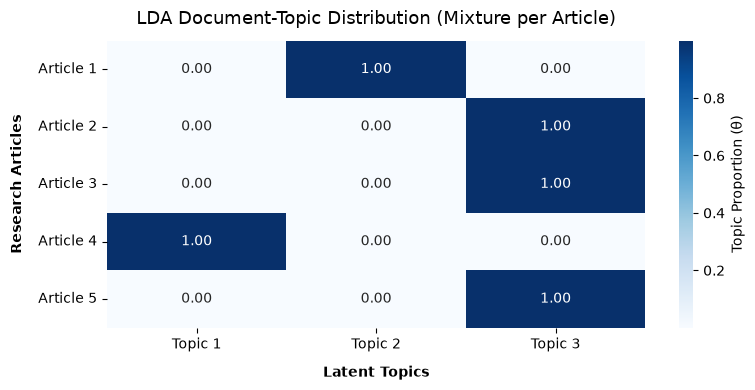

In [31]:
# Visualisation 2: Document-Topic Distribution Heatmap 

# Extract the topic mixture distribution (theta) for each document 
doc_topic_probs = [] 
for bow in bow_corpus: 
    row = dict(ldamodel.get_document_topics(bow, minimum_probability=0)) 
    doc_topic_probs.append([row.get(t, 0.0) for t in range(num_topics)]) 
    
doc_topic_df = pd.DataFrame( 
    doc_topic_probs, 
    columns=[f"Topic {i+1}" for i in range(num_topics)], 
    index=[f"Article {i+1}" for i in range(len(df))], 
) 

plt.figure(figsize=(max(8, num_topics * 2.5), max(4, len(df) * 0.45)))

sns.heatmap( 
    doc_topic_df, 
    annot=True, 
    fmt=".2f", 
    cmap="Blues", 
    cbar_kws={"label": "Topic Proportion (θ)"}, 
) 

plt.title("LDA Document-Topic Distribution (Mixture per Article)", fontsize=13, pad=12) 
plt.xlabel("Latent Topics", fontweight="bold", labelpad=10) 
plt.yticks(rotation=0)
plt.ylabel("Research Articles", fontweight="bold", labelpad=10) 
plt.tight_layout() 
plt.show()

### 4.2.

In [32]:
# Import Gensim bridge
try: 
    import pyLDAvis.gensim_models as gensimvis 
except (ImportError, ModuleNotFoundError): 
    import pyLDAvis.gensim as gensimvis 
    
pyLDAvis.enable_notebook()

vis_data = gensimvis.prepare( 
    ldamodel, 
    bow_corpus, 
    dictionary, 
    sort_topics=False, 
    mds='mmds' # or 'pcoa' 
)

# Save as a standalone interactive HTML file
pyLDAvis.save_html(vis_data, 'lda_intertopic_distance_map.html') 
print("Interactive map saved to 'lda_intertopic_distance_map.html'") 

# Display 
pyLDAvis.display(vis_data)

Interactive map saved to 'lda_intertopic_distance_map.html'


### 4.3.

GitHub repository: https://github.com/dimpho-01/itnpa4-34.git